In [1]:
import pandas as pd
import numpy as np


In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#importing dataset
df = pd.read_csv("/content/india_housing_prices.csv")

In [3]:
df

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64014,64015,Punjab,Ludhiana,Locality_477,Villa,5,3112,141.24,0.05,2012,...,13,2,9,Medium,No,Yes,"Gym, Clubhouse, Pool",South,Builder,Under_Construction
64015,64016,Odisha,Cuttack,Locality_290,Independent House,2,3182,157.28,0.05,1995,...,30,1,2,Low,Yes,No,"Playground, Gym, Pool, Garden, Clubhouse",East,Owner,Ready_to_Move
64016,64017,West Bengal,Durgapur,Locality_207,Villa,5,1198,420.63,0.35,2020,...,5,6,4,Medium,No,Yes,"Garden, Gym",South,Builder,Under_Construction
64017,64018,Chhattisgarh,Raipur,Locality_490,Villa,5,2472,53.83,0.02,1999,...,26,3,6,Medium,Yes,No,Clubhouse,North,Broker,Ready_to_Move


In [4]:
# 2. Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.replace(r"[^\w]+", "_", regex=True)
)

In [5]:
# 3. Remove duplicate rows
df.drop_duplicates(inplace=True)

In [6]:
# 4. Clean text columns
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)

In [7]:
# 5. Handle missing values
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    mode = df[col].mode()
    if not mode.empty:
        df[col] = df[col].fillna(mode[0])

In [8]:
# 6. Standardize category values
category_cols = [
    "State", "City", "Locality", "Property_Type",
    "Furnished_Status", "Public_Transport_Accessibility",
    "Parking_Space", "Security", "Facing",
    "Owner_Type", "Availability_Status"
]

for col in category_cols:
    df[col] = df[col].str.title()

In [9]:
# 7. Convert numeric columns
numeric_cols = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs",
    "Year_Built", "Floor_No", "Total_Floors",
    "Nearby_Schools", "Nearby_Hospitals"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [10]:
# 8. Remove rows with invalid core values
df = df.dropna(
    subset=["BHK", "Size_in_SqFt",
            "Price_in_Lakhs", "Year_Built"]
)

df = df[
    (df["BHK"] > 0) &
    (df["Size_in_SqFt"] > 0) &
    (df["Price_in_Lakhs"] > 0) &
    (df["Year_Built"] <= pd.Timestamp.today().year)
].copy()

In [11]:
# 9. Feature engineering: property age
current_year = pd.Timestamp.today().year

df["Age_of_Property"] = (
    current_year - df["Year_Built"]
).clip(lower=0)

In [12]:
# 10. Feature engineering: price per square foot
df["Price_per_SqFt_Rs"] = (
    df["Price_in_Lakhs"] * 100000 /
    df["Size_in_SqFt"]
).round(2)

In [13]:
# 11. Feature engineering: age group
df["Property_Age_Group"] = pd.cut(
    df["Age_of_Property"],
    bins=[-1, 5, 10, 20, 100],
    labels=[
        "New", "Recent", "Established", "Older"
    ]
)

In [14]:
# 12. Feature engineering: size category
df["Size_Category"] = pd.cut(
    df["Size_in_SqFt"],
    bins=[0, 800, 1500, 2500, np.inf],
    labels=[
        "Small", "Medium", "Large", "Very Large"
    ]
)


In [15]:
# 13. Feature engineering: price category
df["Price_Category"] = pd.cut(
    df["Price_in_Lakhs"],
    bins=[0, 50, 100, 250, np.inf],
    labels=[
        "Budget", "Affordable", "Premium", "Luxury"
    ]
)

In [16]:
# 14. BHK density per 1000 square feet
df["BHK_per_1000_SqFt"] = (
    df["BHK"] / (df["Size_in_SqFt"] / 1000)
).round(2)


In [17]:
# 15. Count the amenities
df["Amenities"] = df["Amenities"].fillna("None")

df["Amenity_Count"] = df["Amenities"].apply(
    lambda x: 0 if str(x).strip().lower() in
    ["", "none", "nan"]
    else len([
        item for item in str(x).split(",")
        if item.strip()
    ])
)

In [18]:

# 16. Convert Yes/No columns to binary features
df["Has_Parking"] = (
    df["Parking_Space"].str.lower().map(
        {"yes": 1, "no": 0}
    )
)

df["Has_Security"] = (
    df["Security"].str.lower().map(
        {"yes": 1, "no": 0}
    )
)

df["Is_Ready_To_Move"] = (
    df["Availability_Status"]
    .str.lower()
    .eq("ready_to_move")
    .astype(int)
)

In [19]:
# 17. Flag inconsistent floor data
df["Floor_Data_Check"] = np.where(
    df["Floor_No"] > df["Total_Floors"],
    "Review", "OK"
)

In [20]:
# 18. Log-transform price for possible ML modelling
df["Log_Price_in_Lakhs"] = np.log1p(
    df["Price_in_Lakhs"]
)

In [21]:
# 19. Drop unnecessary ID column
df.drop(columns=["ID"], inplace=True, errors="ignore")


In [22]:
# 20. Final validation
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", df.duplicated().sum())
print("\nCleaned dataset preview:")
print(df.head())

Dataset shape: (64019, 33)

Missing values:
State               0
City                0
Locality            0
Property_Type       0
BHK                 0
Size_in_SqFt        0
Price_in_Lakhs      0
Price_per_SqFt      0
Year_Built          0
Furnished_Status    0
dtype: int64

Duplicate rows: 0

Cleaned dataset preview:
         State      City      Locality      Property_Type  BHK  Size_in_SqFt  \
0   Tamil Nadu   Chennai   Locality_84          Apartment    1          4740   
1  Maharashtra      Pune  Locality_490  Independent House    3          2364   
2       Punjab  Ludhiana  Locality_167          Apartment    2          3642   
3    Rajasthan   Jodhpur  Locality_393  Independent House    2          2741   
4    Rajasthan    Jaipur  Locality_466              Villa    4          4823   

   Price_in_Lakhs  Price_per_SqFt  Year_Built Furnished_Status  ...  \
0          489.76            0.10        1990        Furnished  ...   
1          195.52            0.08        2008      Unfu

In [29]:
# Basic exploration
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())

         State      City      Locality      Property_Type  BHK  Size_in_SqFt  \
0   Tamil Nadu   Chennai   Locality_84          Apartment    1          4740   
1  Maharashtra      Pune  Locality_490  Independent House    3          2364   
2       Punjab  Ludhiana  Locality_167          Apartment    2          3642   
3    Rajasthan   Jodhpur  Locality_393  Independent House    2          2741   
4    Rajasthan    Jaipur  Locality_466              Villa    4          4823   

   Price_in_Lakhs  Price_per_SqFt  Year_Built Furnished_Status  ...  \
0          489.76            0.10        1990        Furnished  ...   
1          195.52            0.08        2008      Unfurnished  ...   
2          183.79            0.05        1997   Semi-Furnished  ...   
3          300.29            0.11        1991        Furnished  ...   
4          182.90            0.04        2002   Semi-Furnished  ...   

   Property_Age_Group  Size_Category  Price_Category  BHK_per_1000_SqFt  \
0               O

**Understand whether most properties are affordable, mid-range, or luxury properties.**

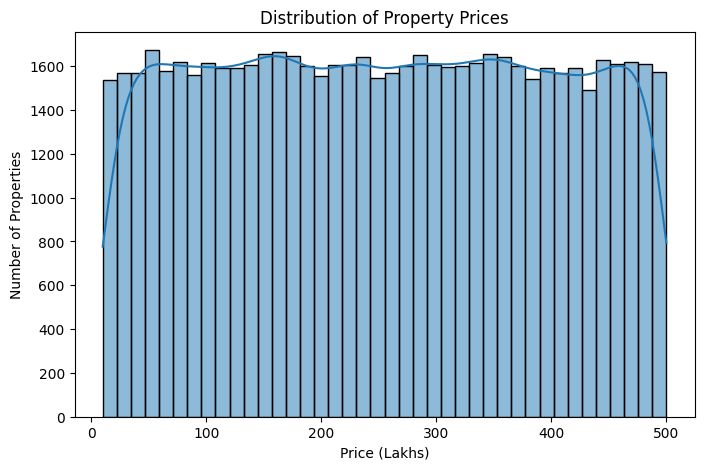

In [33]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Price_in_Lakhs", bins=40, kde=True)
plt.title("Distribution of Property Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Properties")
plt.show()

**Compare the average price of apartments, independent houses, and other property types.**

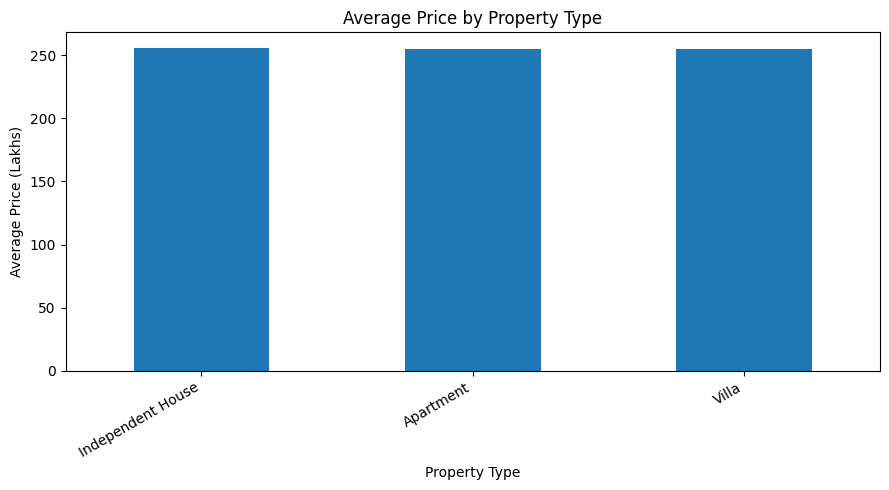

In [34]:
avg_price = df.groupby("Property_Type")["Price_in_Lakhs"].mean().sort_values(ascending=False)

avg_price.plot(kind="bar", figsize=(9, 5))
plt.title("Average Price by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Compare price spread, median prices, and unusually expensive properties for different bedroom counts.**

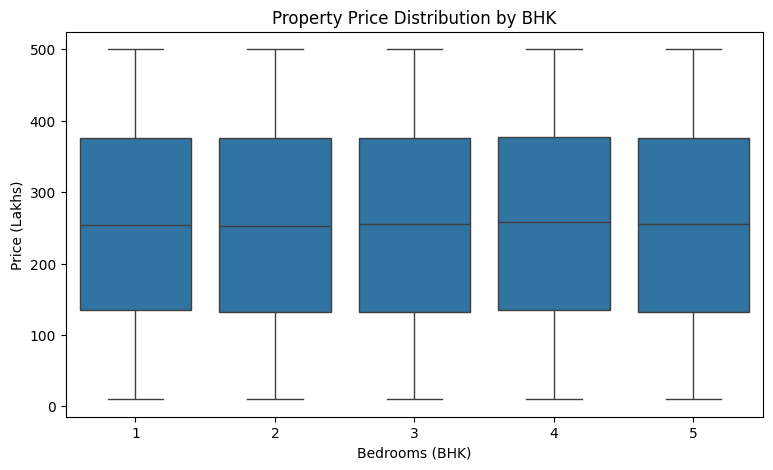

In [35]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="BHK", y="Price_in_Lakhs")
plt.title("Property Price Distribution by BHK")
plt.xlabel("Bedrooms (BHK)")
plt.ylabel("Price (Lakhs)")
plt.show()

**Explore price differences across construction years. This shows a historical relationship, not necessarily annual market appreciation.**

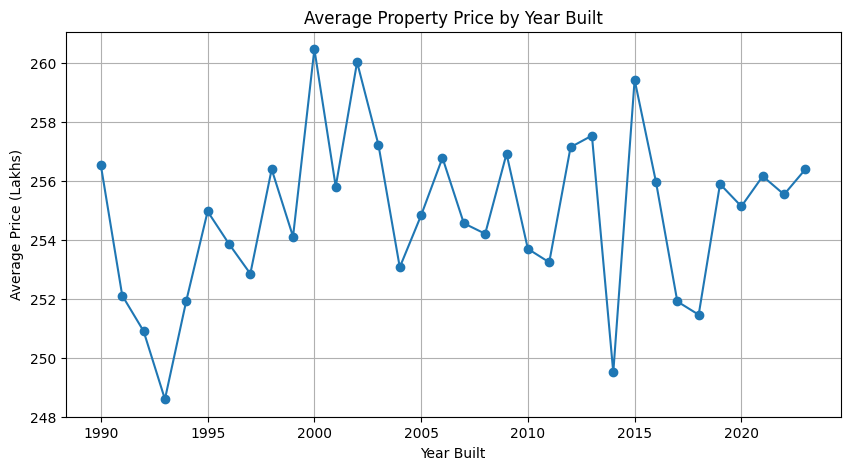

In [37]:
year_price = df.groupby("Year_Built")["Price_in_Lakhs"].mean()

plt.figure(figsize=(10, 5))
plt.plot(year_price.index, year_price.values, marker="o")
plt.title("Average Property Price by Year Built")
plt.xlabel("Year Built")
plt.ylabel("Average Price (Lakhs)")
plt.grid(True)
plt.show()

**Find numerical features associated with property price and identify relationships between variables.**

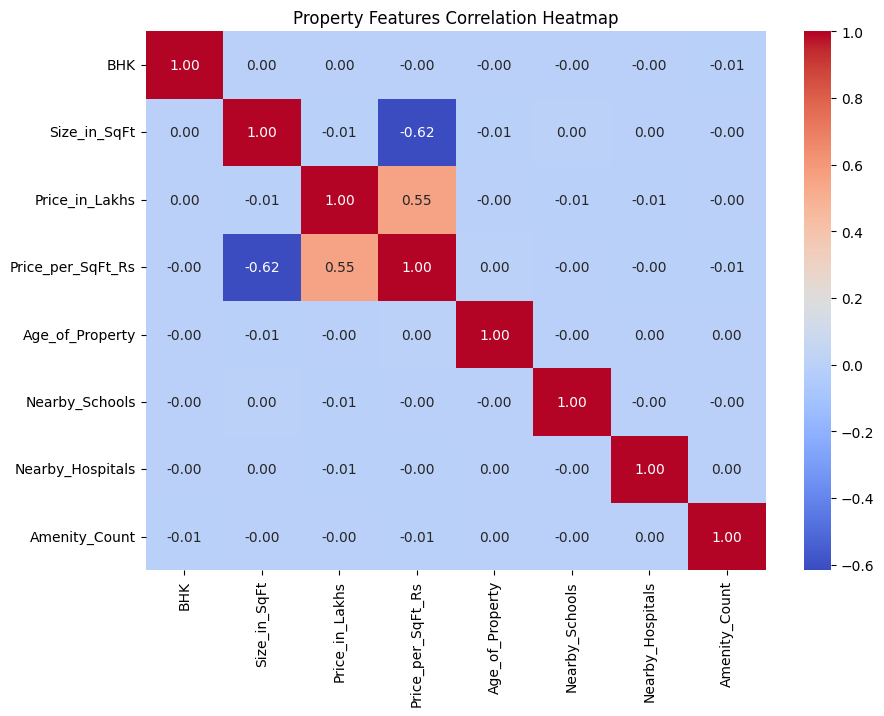

In [38]:
cols = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs",
    "Price_per_SqFt_Rs", "Age_of_Property",
    "Nearby_Schools", "Nearby_Hospitals", "Amenity_Count"
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[cols].corr(numeric_only=True),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Property Features Correlation Heatmap")
plt.show()

**Identify cities with the most listings in the dataset.**

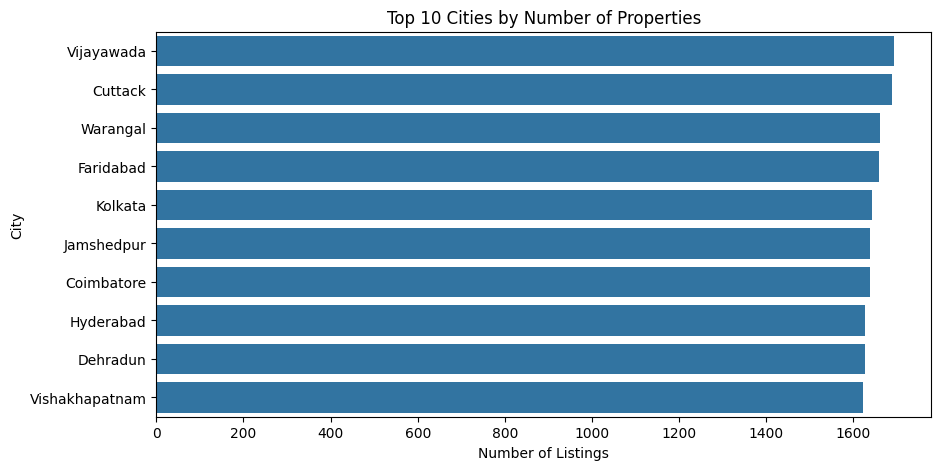

In [39]:
top_cities = df["City"].value_counts().head(10).index

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df[df["City"].isin(top_cities)],
    y="City", order=top_cities
)
plt.title("Top 10 Cities by Number of Properties")
plt.xlabel("Number of Listings")
plt.ylabel("City")
plt.show()

**Compare property prices after accounting for size, making city-level comparisons more meaningful.**

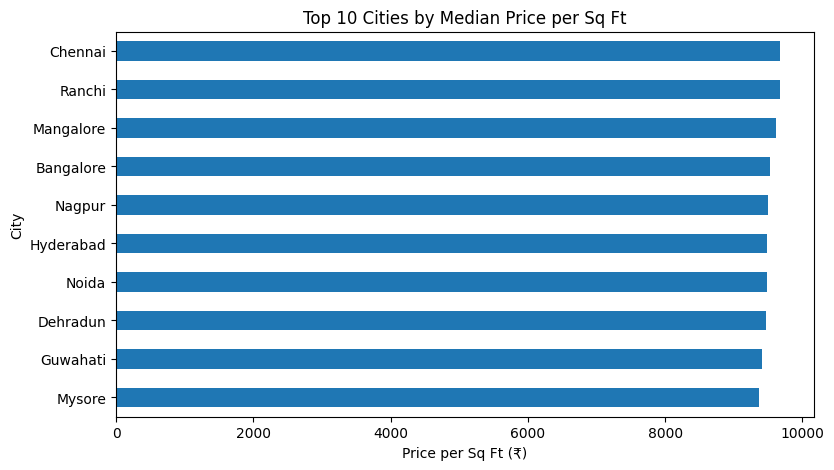

In [40]:
city_price = (
    df.groupby("City")["Price_per_SqFt_Rs"]
      .median()
      .sort_values(ascending=False)
      .head(10)
)

city_price.sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 Cities by Median Price per Sq Ft")
plt.xlabel("Price per Sq Ft (₹)")
plt.ylabel("City")
plt.show()

**Understand the proportion of furnished, semi-furnished, and unfurnished properties.**

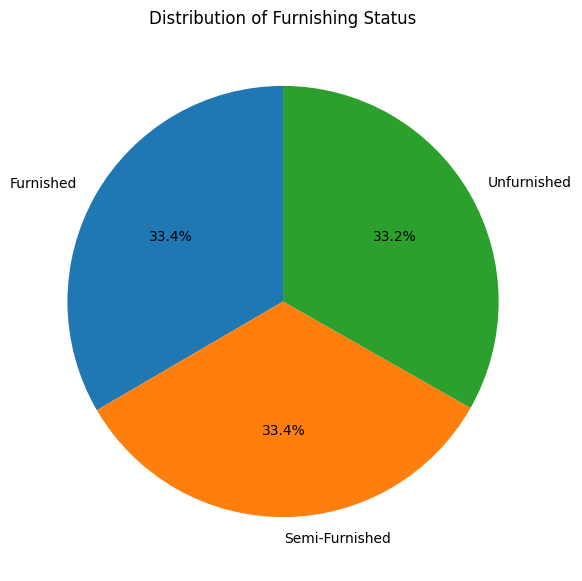

In [41]:
df["Furnished_Status"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    startangle=90
)
plt.title("Distribution of Furnishing Status")
plt.ylabel("")
plt.show()

**Compare the distribution and density of prices across furnishing categories.**

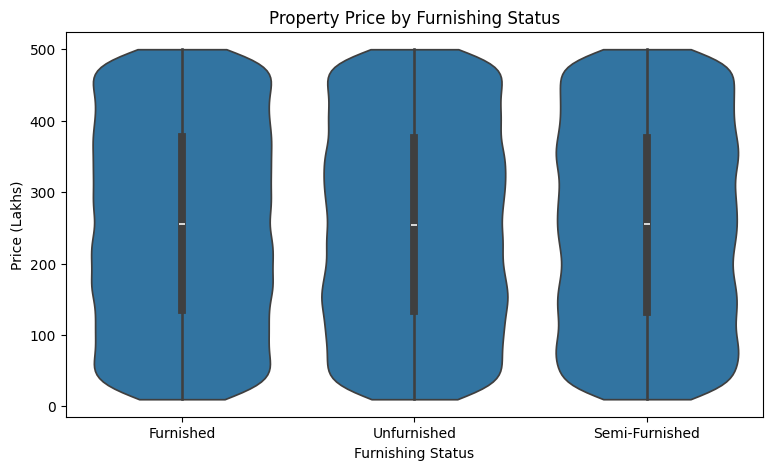

In [42]:
plt.figure(figsize=(9, 5))
sns.violinplot(
    data=df, x="Furnished_Status", y="Price_in_Lakhs",
    cut=0
)
plt.title("Property Price by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Price (Lakhs)")
plt.show()

**Compare ready-to-move and under-construction properties across property types.**

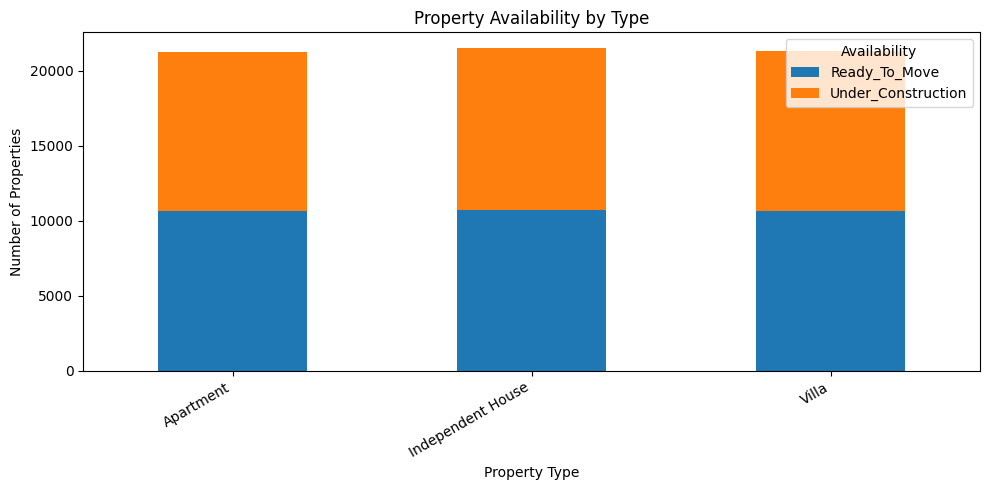

In [43]:
availability = pd.crosstab(
    df["Property_Type"],
    df["Availability_Status"]
)

availability.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Property Availability by Type")
plt.xlabel("Property Type")
plt.ylabel("Number of Properties")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Availability")
plt.tight_layout()
plt.show()

**Explore how nearby schools, hospitals, and property prices vary together. Bubble size represents property price.**

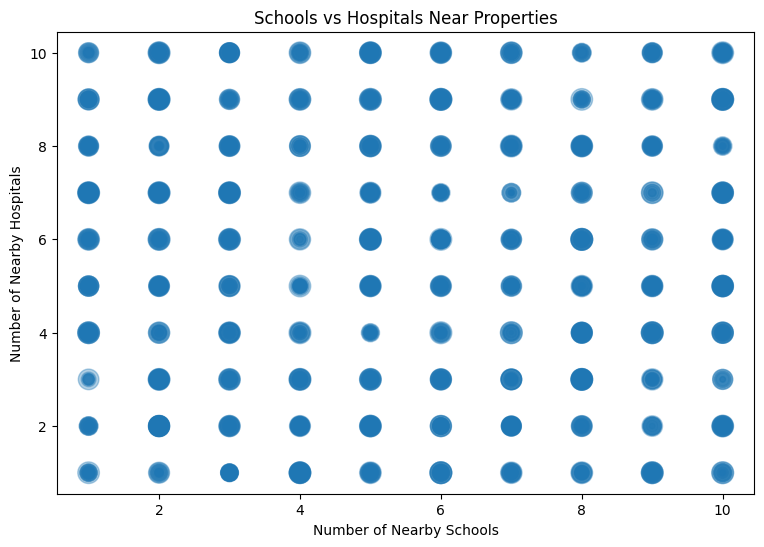

In [44]:
sample = df.sample(min(1500, len(df)), random_state=42)

plt.figure(figsize=(9, 6))
plt.scatter(
    sample["Nearby_Schools"],
    sample["Nearby_Hospitals"],
    s=sample["Price_in_Lakhs"].clip(lower=1) * 0.5,
    alpha=0.35
)
plt.title("Schools vs Hospitals Near Properties")
plt.xlabel("Number of Nearby Schools")
plt.ylabel("Number of Nearby Hospitals")
plt.show()

**Identify the size ranges where properties are most concentrated.**

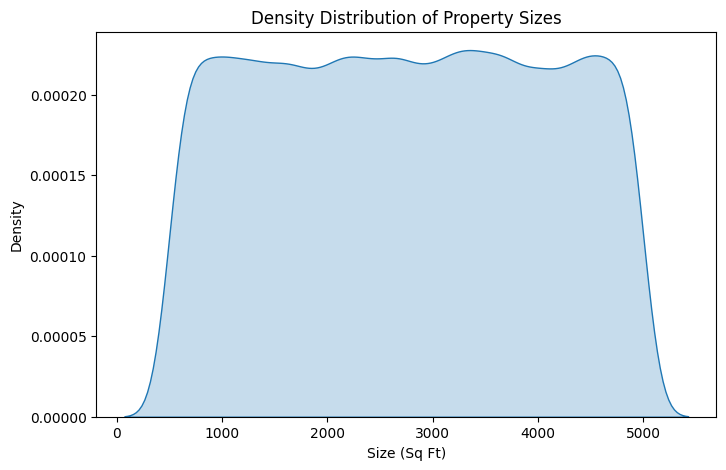

In [45]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x="Size_in_SqFt", fill=True)
plt.title("Density Distribution of Property Sizes")
plt.xlabel("Size (Sq Ft)")
plt.ylabel("Density")
plt.show()

**Compare average property prices in locations with high, medium, and low public transport accessibility.**

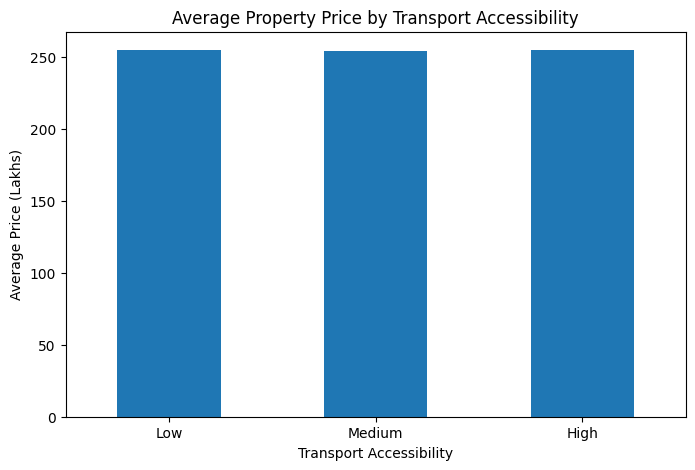

In [46]:
transport_price = (
    df.groupby("Public_Transport_Accessibility")["Price_in_Lakhs"]
      .mean()
      .reindex(["Low", "Medium", "High"])
      .dropna()
)

transport_price.plot(kind="bar", figsize=(8, 5))
plt.title("Average Property Price by Transport Accessibility")
plt.xlabel("Transport Accessibility")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=0)
plt.show()

**Explore several numerical relationships at once, including price, size, BHK, and property age.**

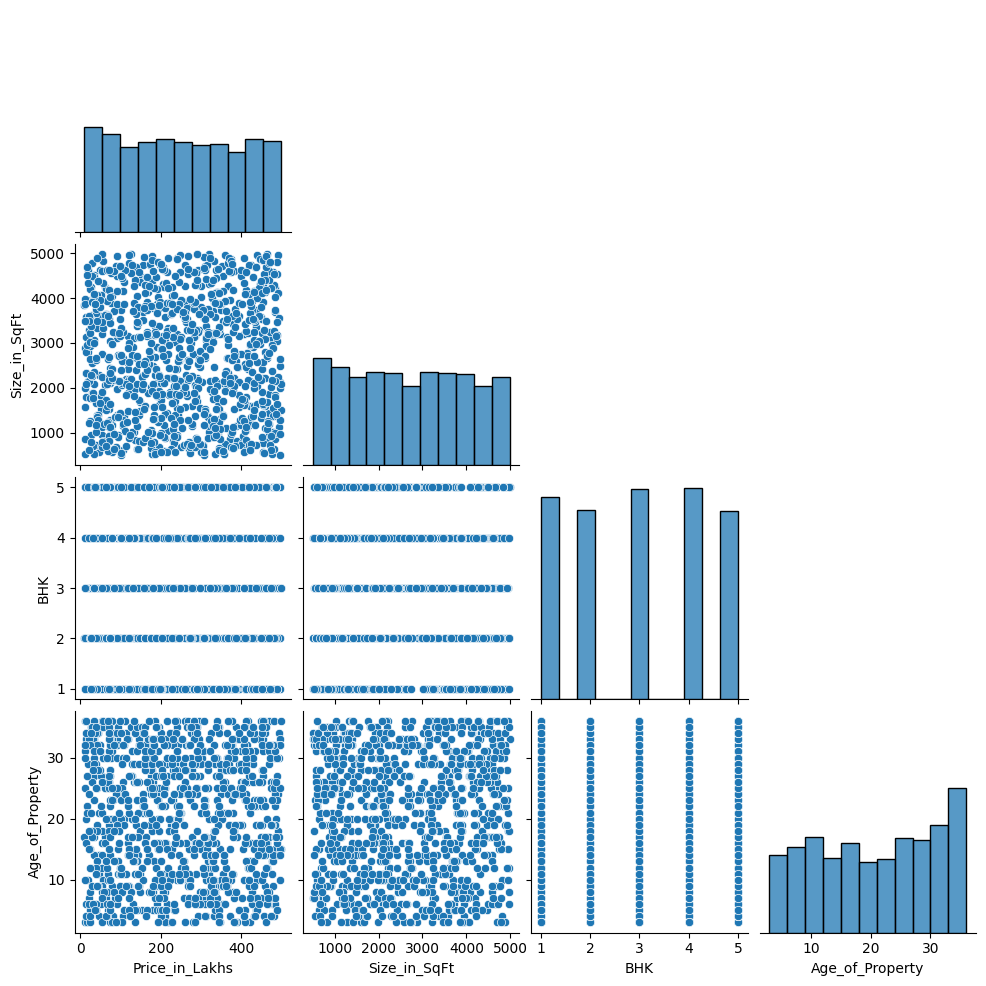

In [47]:
features = [
    "Price_in_Lakhs",
    "Size_in_SqFt",
    "BHK",
    "Age_of_Property"
]

sns.pairplot(
    df[features].sample(min(1000, len(df)), random_state=42),
    diag_kind="hist",
    corner=True
)

plt.show()